# 08 · VaLLA: fixed inducing residuals and coherent linearized predictions

A standalone tutorial using the maintained `laplace_hypopinn` package. [Tutorial index](README.md) · [Method definitions](../../docs/methods.md)

## Goal

Learn the full path from synthetic receiver observations to a trained travel-time field, a local parameter distribution, and sampled source locations. The figures and checks below are generated by the displayed code.

This adaptation freezes the trained center, prior/damping, likelihood weights,
and distinct inducing **residual rows**. Complete residual Jacobians are
whitened by $\sqrt{s\alpha_i}$. Only a lower-triangular covariance factor
$L$ is optimized; inducing locations, model parameters, noise scales, and
hyperparameters stay fixed. For the whitened inducing Jacobian $J_z$,

$$
K_{zz}=J_zJ_z^{\top}/\lambda,\qquad
H=I+L^{\top}K_{zz}L,\qquad
A=L\operatorname{solve}(H,L^{\top}),
$$
$$
\operatorname{Cov}(f_x)=K_{xx}-K_{xz}AK_{xz}^{\top},\qquad
C_\theta=(\lambda I+J_z^{\top}LL^{\top}J_z)^{-1}.
$$

The implementation evaluates these identities with positive QR feature-space
variance calculations, avoiding cancellation from subtracting large kernels.
Work caches and the small variational calculation use float64 on the same
device; posterior tensors retain the model dtype. No dense grid covariance
or full parameter-space orthogonal basis is constructed.

For whitened residual mean $r_i$ and variance $v_i$, the optimized
objective sums $\tfrac12(r_i^2+v_i)$ for `alpha=0` (ELBO limit), or
$\tfrac12\log(1+v_i)+\tfrac12r_i^2/(1+v_i)$ for `alpha=1`, plus the
covariance-dependent Gaussian KL. This divergence setting is distinct from
the residual weights $\alpha_i$. The tutorial starts with 32 inducing rows,
100 Adam steps, and `alpha=0`; these are teaching budgets, not convergence
guarantees or publication reproduction settings.

The API calls the frozen center "MAP". With zero training prior, the
tutorial's $\lambda=1000$, $s=1$ are post-hoc damping; the center need
not be the MAP of that regularized model. Prediction uses
$T_{\rm center}(q)+J_T(q)\delta$, with the **same** $\delta$ reused
across every chunk of a complete field. Evaluating nonlinear networks at
perturbed weights is a different convention.

Source: [Ortega, Rodriguez-Santana and Hernandez-Lobato (ICML 2024),
*Variational Linearized Laplace Approximation for Bayesian Deep
Learning*](https://proceedings.mlr.press/v235/ortega24a.html).
This repository uses fixed inducing PINN residual functionals rather than
claiming the publication's learned inducing variables or benchmark results;
see [the precise adaptation](../../docs/methods.md#valla-fixed-inducing-pinn-residual-adaptation).


## Setup

From the repository root, install `python -m pip install -e ".[notebooks]" jupyterlab`, then register/select that environment’s kernel with `python -m ipykernel install --sys-prefix --name laplace-hypopinn`. Open this notebook in JupyterLab or an editor and **Restart Kernel → Run All**. No downloads, GPU, external dataset, or previous tutorial outputs are required.

This synthetic example uses `(z, x)` coordinates in **km**, velocity in **km/s**, and travel time in **s**.

In [1]:
%matplotlib inline
from dataclasses import replace
import importlib.metadata
import platform
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Markdown, display

from laplace_hypopinn.config import LaplaceConfig, resolve_dtype
from laplace_hypopinn.curvature.residuals import make_residual_plan
from laplace_hypopinn.data import prepare_problem, sample_training_batch
from laplace_hypopinn.losses import loss_terms
from laplace_hypopinn.model import flatten_parameters, initialize_model, make_mlp_forward
from laplace_hypopinn.prediction import grid_location, predict_grid, sample_locations
from laplace_hypopinn.presets import load_preset
from laplace_hypopinn.training import train
from laplace_hypopinn.types import RandomStreams

torch.set_num_threads(1)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": False})
colors = {"map": "#0072B2", "truth": "#222222", "posterior": "#56B4E9",
          "receiver": "#E69F00"}

def as_numpy(tensor):
    return tensor.detach().cpu().numpy()

def spatial_axes(ax):
    ax.set(xlabel="Horizontal distance x (km)", ylabel="Depth z (km)",
           xlim=(x[0], x[-1]), ylim=(z[-1], z[0]))
    ax.set_aspect("equal")

def source_markers(ax, *, include_center=False):
    ax.scatter(receivers[:, 1], receivers[:, 0], marker="v", s=45,
               color=colors["receiver"], edgecolors="black", clip_on=False,
               zorder=4, label="Receivers")
    ax.scatter(truth[1], truth[0], marker="X", s=75, facecolor="white",
               edgecolor=colors["truth"], zorder=5, label="Known source")
    if include_center:
        ax.scatter(center_location[1], center_location[0], marker="*", s=120,
                   color=colors["map"], edgecolors="black", zorder=6,
                   label="Trained minimum")

print(f"Python {platform.python_version()} | torch {torch.__version__} | "
      f"NumPy {np.__version__} | laplace-hypopinn "
      f"{importlib.metadata.version('laplace-hypopinn')}")

Python 3.12.14 | torch 2.5.1+cpu | NumPy 1.26.4 | laplace-hypopinn 0.1.0


### Choose an explicit teaching budget

The architecture and grid are the EX2 notebook preset: `(2,16,16,32,32,16,16,1)` with Mish and a `101 × 151` grid. We use **800 training updates**, **512 collocation points**, and **64 posterior draws** for a short CPU lesson. Historical reproduction uses 3,001 updates, 2,501 collocations and 1,000 draws; the legacy curvature budget is also reduced here. These changes affect fitted fields and uncertainty.

Training has no parameter prior. The positive posterior regularizer is therefore **post-hoc damping**, not a claim that the trained center is the MAP of that regularized posterior. Values are demonstration settings, not calibrated physical noise or prior estimates.

In [2]:
base = load_preset("ex2")
config = replace(
    base, name="tutorial_valla", device="cpu", dtype="float32",
    data=replace(base.data, collocation_count=512),
    training=replace(base.training, steps=800, log_every=20),
    laplace=LaplaceConfig(
    method="valla", samples=64,
    prior_precision=1000.0, scale=1.0, chunk_size=32, max_dense_bytes=256*1024**2,
    inducing_count=32, variational_steps=100, variational_lr=0.01, alpha=0,
    ),
    prediction_chunk_size=4096, posterior_batch_size=4,
)
print(f"Widths: {config.model.widths}; activation: {config.model.activation}")
print(f"Training updates: {config.training.steps}; samples: {config.laplace.samples}; seed: {config.seed}")

Widths: (2, 16, 16, 32, 32, 16, 16, 1); activation: mish
Training updates: 800; samples: 64; seed: 4321


## Steps

### 1. Prepare data and initialize the model

The gradient-velocity problem generates analytic travel times and receiver observations. Training uses receiver observations, known velocity through the eikonal residual, and the positivity penalty; the known source and complete reference field are evaluation aids. A fixed collocation batch and local random streams make top-to-bottom execution reproducible.

2,737 parameters; 101 × 151 grid; 512 fixed collocation points; 11 receivers
Grid spacing: dz=0.020 km, dx=0.020 km


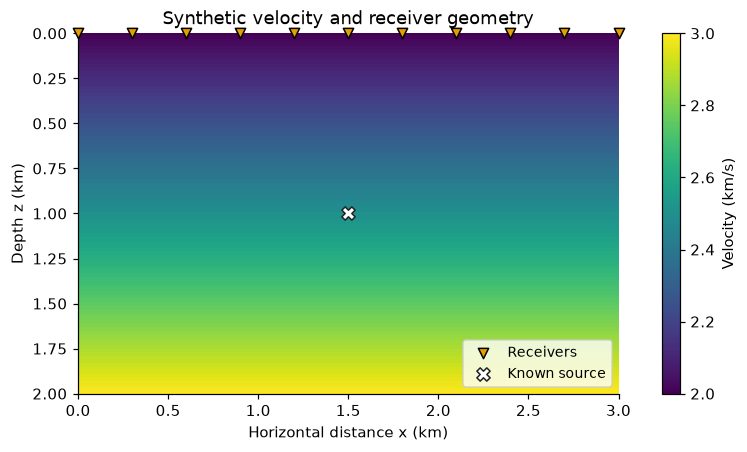

In [3]:
problem = prepare_problem(config)
streams = RandomStreams(config.seed, config.device)
initial_parameters = initialize_model(
    config.model.widths, config.model.initialization, streams,
    dtype=resolve_dtype(config.dtype), device=config.device,
)
forward = make_mlp_forward(config.model.activation)
batch = sample_training_batch(problem, config.data.collocation_count, streams)
z, x = as_numpy(problem.grid.z), as_numpy(problem.grid.x)
receivers = as_numpy(problem.receiver_coordinates)
truth = as_numpy(problem.true_source)
reference = as_numpy(problem.reference_times)
parameter_count = flatten_parameters(initial_parameters)[1].numel
print(f"{parameter_count:,} parameters; {len(z)} × {len(x)} grid; "
      f"{len(batch.coordinates)} fixed collocation points; {len(receivers)} receivers")
print(f"Grid spacing: dz={z[1]-z[0]:.3f} km, dx={x[1]-x[0]:.3f} km")

fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
mesh = ax.pcolormesh(x, z, as_numpy(problem.grid.velocity), shading="auto", cmap="viridis")
source_markers(ax)
spatial_axes(ax)
ax.set_title("Synthetic velocity and receiver geometry")
ax.legend(loc="lower right", fontsize=9)
fig.colorbar(mesh, ax=ax, label="Velocity (km/s)")
plt.show()
plt.close(fig)

### 2. Train the shared center

`train` returns new parameters and an optimizer/RNG snapshot. The input mapping remains unchanged. History records pre-update objectives; the final metrics below recompute the objective at the returned parameters.

In [4]:
started = time.perf_counter()
training = train(initial_parameters, batch, config.training, streams, forward=forward)
training_seconds = time.perf_counter() - started
parameters = training.parameters
center_field = predict_grid(parameters, problem.grid, config.prediction_chunk_size, forward=forward)
center_location = as_numpy(grid_location(center_field, problem.grid))
final_terms = loss_terms(parameters, batch, config.training, forward=forward)
field_rmse = float((center_field - problem.reference_times).square().mean().sqrt())
location_error = float(np.linalg.norm(center_location - truth))
with torch.no_grad():
    receiver_prediction = as_numpy(forward(parameters, problem.receiver_coordinates)).reshape(-1)
print(f"Training: {training_seconds:.2f} s; recomputed final objective: {float(final_terms.total.detach()):.3e}")
print(f"Field RMSE: {field_rmse:.5f} s; grid-minimum error: {location_error:.5f} km")
print(f"Trained minimum (z, x): {center_location.round(4)} km")

Training: 5.26 s; recomputed final objective: 5.503e-05
Field RMSE: 0.02246 s; grid-minimum error: 0.05657 km
Trained minimum (z, x): [1.04 1.54] km


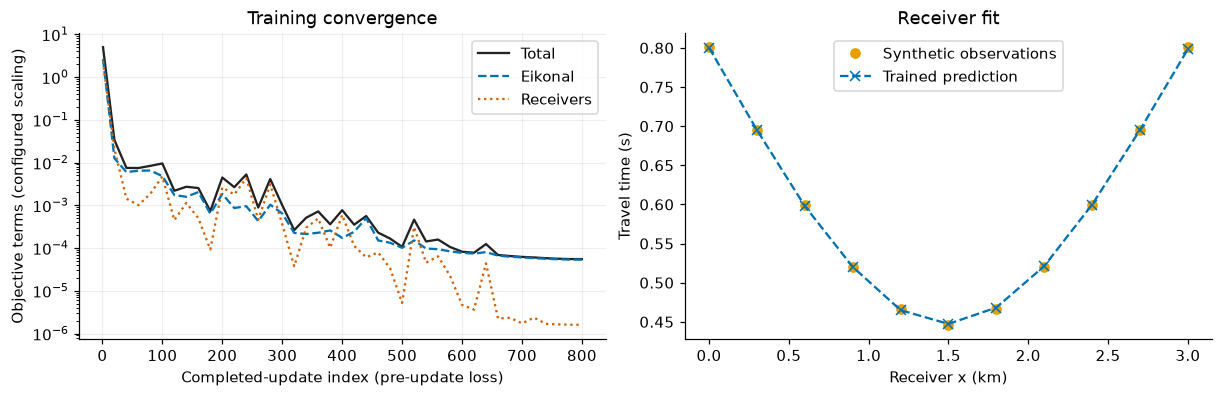

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
steps = [entry["step"] for entry in training.history]
for key, label, color, style in (
    ("total", "Total", "#222222", "-"),
    ("pde", "Eikonal", "#0072B2", "--"),
    ("data", "Receivers", "#D55E00", ":"),
):
    axes[0].semilogy(steps, [entry[key] for entry in training.history],
                     label=label, color=color, linestyle=style)
axes[0].set(xlabel="Completed-update index (pre-update loss)",
            ylabel="Objective terms (configured scaling)", title="Training convergence")
axes[0].legend()
axes[0].grid(alpha=.2)
axes[1].plot(receivers[:, 1], as_numpy(problem.receiver_times).reshape(-1),
             "o", color=colors["receiver"], label="Synthetic observations")
axes[1].plot(receivers[:, 1], receiver_prediction, "x--", color=colors["map"],
             label="Trained prediction")
axes[1].set(xlabel="Receiver x (km)", ylabel="Travel time (s)", title="Receiver fit")
axes[1].legend()
plt.show()
plt.close(fig)

Receiver agreement alone does not establish an accurate interior field. Compare the trained field with the analytic reference using one shared color scale, and inspect the signed error separately. A white X marks the known source; a blue star marks the trained grid minimum.

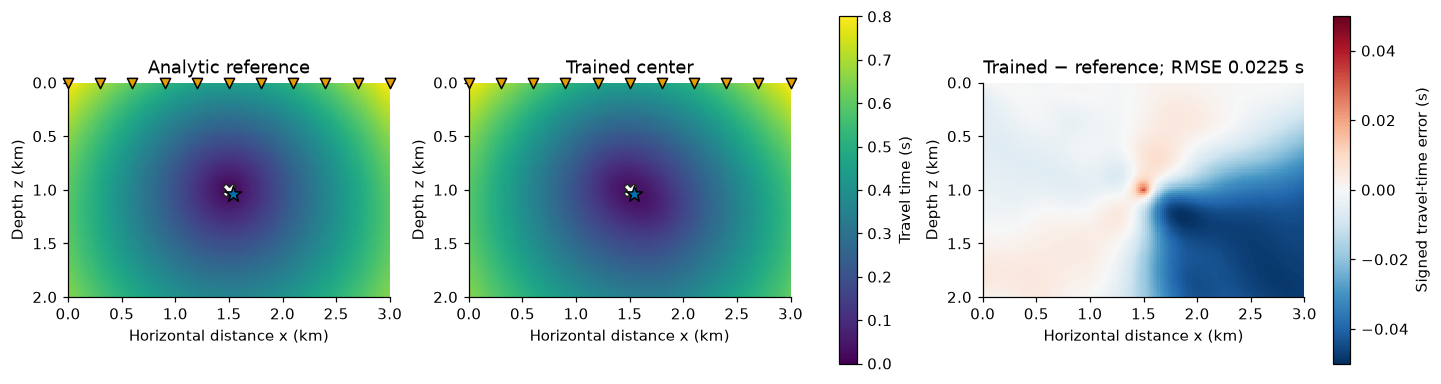

In [6]:
trained = as_numpy(center_field)
low, high = min(reference.min(), trained.min()), max(reference.max(), trained.max())
error = trained - reference
error_limit = max(float(np.abs(error).max()), np.finfo(float).eps)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), layout="constrained")
for ax, values, title in zip(axes[:2], (reference, trained),
                            ("Analytic reference", "Trained center"), strict=True):
    mesh = ax.pcolormesh(x, z, values, shading="auto", cmap="viridis", vmin=low, vmax=high)
    source_markers(ax, include_center=True)
    spatial_axes(ax)
    ax.set_title(title)
fig.colorbar(mesh, ax=axes[:2], label="Travel time (s)", shrink=.85)
mesh = axes[2].pcolormesh(x, z, error, shading="auto", cmap="RdBu_r",
                         vmin=-error_limit, vmax=error_limit)
spatial_axes(axes[2])
axes[2].set_title(f"Trained − reference; RMSE {field_rmse:.4f} s")
fig.colorbar(mesh, ax=axes[2], label="Signed travel-time error (s)", shrink=.85)
plt.show()
plt.close(fig)

### 3. Fit the selected curvature approximation

Corrected methods use a **fixed residual plan**, with global family weights applied before chunking. The legacy method instead resamples coordinates and squares the total loss gradient. The following cell calls the method’s public API directly; it does not execute archived notebook code.

In [7]:
from laplace_hypopinn.curvature.valla import fit_valla

plan = make_residual_plan(batch, config.training)
# Separate streams keep curvature selection independent of training and prediction.
streams = RandomStreams(config.seed + 1, config.device)
started = time.perf_counter()

# Selection uses the supplied local NumPy stream; the selected identities are recorded.
# The center and inducing rows stay fixed; fit_valla optimizes only triangular L.
fit_started = time.perf_counter()
posterior = fit_valla(
    parameters, plan, config.laplace, streams, forward=forward,
)
fit_seconds = time.perf_counter() - fit_started
print(f"VaLLA cache construction and variational fit: {fit_seconds:.3f} s")
print("Requested/effective inducing rows:",
      posterior.metadata["requested_inducing_count"],
      posterior.metadata["effective_inducing_count"])
print("Fixed quantities:", posterior.metadata["fixed"])
print("Prediction:", posterior.metadata["prediction_convention"])
print("Work precision:", posterior.metadata["variance_work_dtype"])

fit_seconds = time.perf_counter() - started
print(f"Curvature fit: {fit_seconds:.2f} s; representation: {posterior.representation}")

VaLLA cache construction and variational fit: 0.522 s
Requested/effective inducing rows: 32 32
Fixed quantities: ('MAP', 'prior_precision', 'residual_weights', 'inducing_rows')
Prediction: T_MAP(x) + J_T(x) @ delta; one delta per complete field
Work precision: float64 (same device); public results retain model dtype
Curvature fit: 0.52 s; representation: low_rank


### Inspect the method’s structure

The history includes step zero and the objective after every update. A decline
is evidence about this finite optimization run; it is not a convergence or
calibration certificate. The absolute objective includes a fixed-center data
term, so compare like-for-like residual plans and divergence settings.

Inducing rows are selected without replacement from all residual rows;
selection is not stratified by family. A small budget can omit a family.
The histogram and recorded row identities make that choice inspectable.
Row count is not information rank: selected positivity rows can have zero
derivative when the nonnegativity constraint is inactive.
Rebuilding with another seed changes the approximation even when the trained
network is unchanged. Below, the posterior's `linearized` prediction kind
dispatches coherent JVP evaluation: one perturbation defines a complete field.


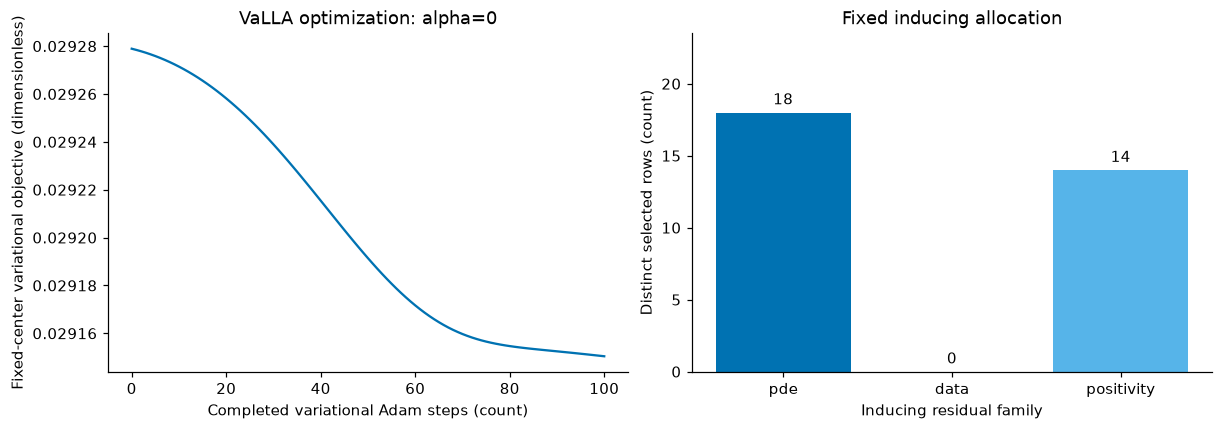

Objective initial/final: 0.029278912 / 0.029150419
Objective change (final - initial): -0.000128493
First 8 inducing identities (plan batch, family, source row): ((1, 'pde', 34), (1, 'pde', 36), (1, 'pde', 50), (1, 'pde', 74), (1, 'pde', 133), (1, 'pde', 154), (1, 'pde', 270), (1, 'pde', 278))
Posterior prediction kind: linearized
Variance roundoff policy: Positive QR feature-space variance; no subtractive cancellation or clipping


In [8]:
history = np.asarray(posterior.metadata["objective_history"])
identities = posterior.metadata["inducing_identities"]
families = ("pde", "data", "positivity")
counts = [sum(identity[1] == family for identity in identities) for family in families]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True)
axes[0].plot(np.arange(len(history)), history, color=colors["map"])
axes[0].set(xlabel="Completed variational Adam steps (count)",
            ylabel="Fixed-center variational objective (dimensionless)",
            title=f'VaLLA optimization: alpha={config.laplace.alpha}')
bars = axes[1].bar(families, counts,
                   color=[colors["map"], colors["receiver"], colors["posterior"]])
axes[1].bar_label(bars, padding=3)
axes[1].set(xlabel="Inducing residual family", ylabel="Distinct selected rows (count)",
            title="Fixed inducing allocation")
axes[1].set_ylim(0, max(counts) * 1.25 + 1)
plt.show()
plt.close(fig)
print(f"Objective initial/final: {history[0]:.8g} / {history[-1]:.8g}")
print(f"Objective change (final - initial): {history[-1] - history[0]:.6g}")
print("First 8 inducing identities (plan batch, family, source row):", identities[:8])
print("Posterior prediction kind:", posterior.prediction_kind)
print("Variance roundoff policy:", posterior.metadata["variance_roundoff_policy"])


### 4. Sample complete fields and source locations

`sample_locations` keeps each parameter perturbation fixed across all grid chunks. It stores grid minima and online field moments instead of a sample-by-grid array. VaLLA evaluates **trained output + parameter JVP**, preserving coherent linearized spatial variation. Every inferred source is a grid minimum; this finite grid limits localization resolution.

In [9]:
# A fresh explicit stream makes this cell reproducible when rerun.
prediction_streams = RandomStreams(config.seed + 2, config.device)
started = time.perf_counter()
summary = sample_locations(posterior, problem.grid, config, prediction_streams.torch)
prediction_seconds = time.perf_counter() - started
locations = as_numpy(summary.locations)
field_mean, field_std = as_numpy(summary.field_mean), as_numpy(summary.field_std)
print(f"Prediction convention: {posterior.prediction_kind}")
print(f"{len(locations)} coherent fields sampled in {prediction_seconds:.2f} s")
print(f"Source-location sample mean (z, x): {as_numpy(summary.mean).round(4)} km")
print(f"Source-location population SD (z, x): {as_numpy(summary.std).round(4)} km")

Prediction convention: linearized
64 coherent fields sampled in 2.59 s
Source-location sample mean (z, x): [1.0906 1.5669] km
Source-location population SD (z, x): [0.1857 0.1343] km


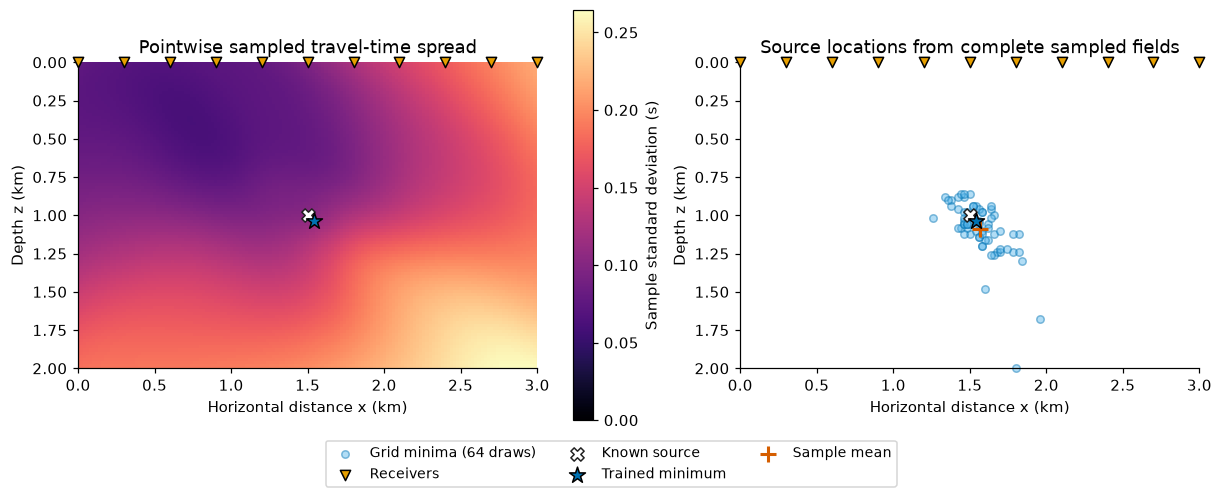

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), layout="constrained")
mesh = axes[0].pcolormesh(x, z, field_std, shading="auto", cmap="magma", vmin=0)
spatial_axes(axes[0])
source_markers(axes[0], include_center=True)
axes[0].set_title("Pointwise sampled travel-time spread")
fig.colorbar(mesh, ax=axes[0], label="Sample standard deviation (s)")
axes[1].scatter(locations[:, 1], locations[:, 0], s=24, alpha=.45,
                color=colors["posterior"], edgecolors=colors["map"], clip_on=False,
                label=f"Grid minima ({len(locations)} draws)")
source_markers(axes[1], include_center=True)
location_mean = as_numpy(summary.mean)
axes[1].scatter(location_mean[1], location_mean[0], marker="+", s=110,
                linewidths=2, color="#D55E00", label="Sample mean")
spatial_axes(axes[1])
axes[1].set_title("Source locations from complete sampled fields")
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=3, fontsize=9)
plt.show()
plt.close(fig)

### Compare uncertainty with field error

The band below is the **sample mean ± two sample standard deviations at each grid point**. It is descriptive spread, **not a 95% credible interval or a simultaneous confidence band**. Negative sampled times are left visible; a Gaussian parameter approximation does not enforce physical positivity. The exact linearized predictive mean is the trained center; the finite-draw sample mean can differ.

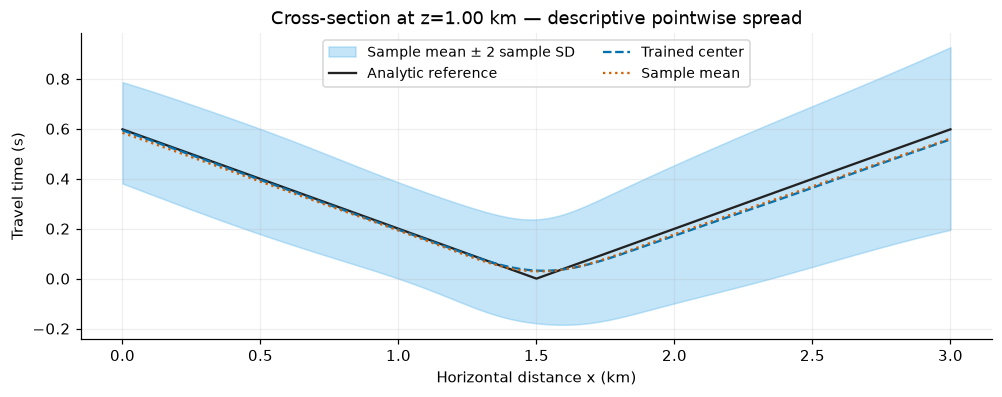

In [11]:
row = int(np.argmin(np.abs(z - truth[0])))
mean_row, std_row = field_mean[row], field_std[row]
fig, ax = plt.subplots(figsize=(9, 3.5), layout="constrained")
ax.fill_between(x, mean_row - 2*std_row, mean_row + 2*std_row,
                 color=colors["posterior"], alpha=.35, label="Sample mean ± 2 sample SD")
ax.plot(x, reference[row], color=colors["truth"], label="Analytic reference")
ax.plot(x, trained[row], "--", color=colors["map"], label="Trained center")
ax.plot(x, mean_row, ":", color="#D55E00", label="Sample mean")
ax.set(xlabel="Horizontal distance x (km)", ylabel="Travel time (s)",
        title=f"Cross-section at z={z[row]:.2f} km — descriptive pointwise spread")
ax.grid(alpha=.2)
ax.legend(ncol=2, fontsize=9)
plt.show()
plt.close(fig)

## Checks

These checks establish finite, internally consistent calculations. They do not test calibration, convergence to a global optimum, or agreement with a full research run.

In [12]:
center_vector, layout = flatten_parameters(parameters)
torch.testing.assert_close(posterior.mean, center_vector.detach(), rtol=0, atol=0)
assert summary.locations.shape == (config.laplace.samples, 2)
assert summary.field_mean.shape == summary.field_std.shape == problem.grid.shape
for value in (center_field, summary.locations, summary.field_mean, summary.field_std):
    assert torch.isfinite(value).all()
assert (summary.field_std >= 0).all()
assert np.isin(locations[:, 0], z).all() and np.isin(locations[:, 1], x).all()
for factor in (posterior.factor, *posterior.blocks):
    if factor is not None:
        assert torch.isfinite(factor).all() and (factor.diag() > 0).all()
if posterior.diagonal is not None:
    assert torch.isfinite(posterior.diagonal).all() and (posterior.diagonal > 0).all()
for _, _, precision in posterior.eigenbasis:
    assert torch.isfinite(precision).all() and (precision > 0).all()
print("Checks passed: finite fields, positive precision, preserved center, and grid-based samples.")
display(Markdown(
    f"**Observed in this run:** field RMSE **{field_rmse:.5f} s**, "
    f"trained grid-minimum error **{location_error:.5f} km**, and "
    f"**{len(locations)}** posterior draws. These are tutorial results; "
    "they do not establish uncertainty calibration or reproduce the paper's full experiments."
))

Checks passed: finite fields, positive precision, preserved center, and grid-based samples.


**Observed in this run:** field RMSE **0.02246 s**, trained grid-minimum error **0.05657 km**, and **64** posterior draws. These are tutorial results; they do not establish uncertainty calibration or reproduce the paper's full experiments.

## Next steps

- Increase `inducing_count` and `variational_steps` separately, recording
  the selected row identities, objective history, runtime, and predictive spread.
- Compare `alpha=0` and `alpha=1` while keeping the trained center, residual
  plan, damping, and inducing selection seed fixed; do not compare absolute
  objective values as if they represented the same objective.
- Repeat inducing selection across several explicit local seeds to measure
  sensitivity to the finite fixed-row approximation and family allocation.
- On a small model, use every residual as inducing with an identity factor
  to check the full linearized GGN covariance identity before optimizing L.
- Keep one perturbation across all prediction chunks; independent per-cell
  draws destroy the spatial correlation required by source localization.


- Change `config.model.widths` or `activation`, then restart and rerun training and curvature. For a custom pointwise model, see the [extension example](../extend_research.py) and [model contract](../../docs/architecture.md). Structured methods need a compatible jet adapter.
- For saved configurations, checkpoints, result arrays and standard plots, use the orchestration API with a **new output directory**:

```python
from laplace_hypopinn.experiment import run_experiment
result = run_experiment(config, output="results/valla-new-run")
```

This starts a new experiment with its own seed schedule; it is not a serializer for the manually computed objects above. Use the [reproducibility guide](../../docs/reproducibility.md) and [measured performance](../../docs/performance.md) before increasing research budgets.